In [1]:
# import modules
import numpy as np
import tensorflow as tf
from tensorflow import keras
import pandas as pd
import seaborn as sns
from pylab import rcParams
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit
from scipy import stats
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split
from tensorflow.keras import optimizers
from datetime import datetime
from kerastuner.tuners import RandomSearch
import tensorflow_addons as tfa
from keras.utils import to_categorical 
from keras.regularizers import l2
from scipy.stats import mode



r_seed = 42

WORKDIR = 'C:/Users/cristiano.nascimento/git/LSTM_giroscopio_acelerometro'
np.random.seed(r_seed)
tf.random.set_seed(r_seed)
data_hora= datetime.now().strftime('%Y-%m-%d_%H-%M-%S')
LOG_DIR = WORKDIR + "/Code/DataPrep/"+data_hora

#pd.set_option('display.float_format', lambda x: f'{x:.17f}')

C:\Users\cristiano.nascimento\AppData\Local\Temp\ipykernel_68672\2651511168.py:15: DeprecationWarning: `import kerastuner` is deprecated, please use `import keras_tuner`.
  from kerastuner.tuners import RandomSearch
c:\Users\cristiano.nascimento\git\LSTM_giroscopio_acelerometro\.venv\lib\site-packages\tensorflow_addons\utils\tfa_eol_msg.py:23: UserWarning: 

TensorFlow Addons (TFA) has ended development and introduction of new features.
TFA has entered a minimal maintenance and release mode until a planned end of life in May 2024.
Please modify downstream libraries to take dependencies from other repositories in our TensorFlow community (e.g. Keras, Keras-CV, and Keras-NLP). 

For more information see: https://github.com/tensorflow/addons/issues/2807 

  warnings.warn(


In [2]:
date = datetime.now()
date = date.strftime("%d/%m/%Y_%H:%M")
arq = datetime.now()
arq = arq.strftime("%d_%m_%Y_%H_%M")

In [3]:
## get dataset
pd.set_option("display.precision", 9)

# select only sensor data from smart watches
data_df = pd.read_csv(WORKDIR+'/Code/DataPrep/kuhar_dataset_transformed.csv',dtype={"value": "float64"})

In [4]:
data_df.shape


(6225000, 7)

In [5]:
data_df.head()

,Acc_X,Acc_Y,Acc_Z,Gyro_X,Gyro_Y,Gyro_Z,Label
0,0.0042305,-0.00028038,-0.0139060,-0.000042764,-0.00081629,-0.0029549,0.0
1,-0.0025436,0.02743300,0.0583000,-0.005450700,-0.00774770,-0.0096927,0.0
2,0.0516700,0.07185700,0.0806530,-0.012871000,-0.01569900,-0.0182940,0.0
3,0.0479170,0.02598000,-0.0045050,-0.020744000,-0.02114700,-0.0245410,0.0
4,-0.0069016,0.00143590,0.0054108,-0.023152000,-0.02181300,-0.0184710,0.0


In [6]:
data_df.tail()

,Acc_X,Acc_Y,Acc_Z,Gyro_X,Gyro_Y,Gyro_Z,Label
6224995,0.810590,-0.260730,-0.42351,0.201280,0.2023200,0.2565900,9.0
6224996,-0.118410,-0.584860,-0.30360,0.297490,0.3196700,0.3674000,9.0
6224997,0.695130,0.372170,-0.16183,0.353460,0.2908100,0.2616200,9.0
6224998,0.097524,-0.074573,-1.56840,0.119120,0.0040946,0.0067546,9.0
6224999,-0.921060,0.385480,0.45310,0.013448,0.0275660,0.1405100,9.0


In [7]:
data_df = data_df.dropna()

In [8]:
data_df.shape

(6225000, 7)

In [9]:
print(data_df['Acc_X'].iloc[0]) 

0.0042305


In [10]:
data_df["Label"].value_counts().sort_index()

Label
0.0     565800
1.0     562200
2.0     539100
3.0     559800
4.0     653400
5.0     543900
6.0     528600
7.0     399900
8.0     199800
9.0     144000
10.0    301500
11.0    264600
12.0     95100
13.0     77700
14.0    178500
15.0    239400
16.0    234300
17.0    137400
Name: count, dtype: int64

In [11]:
data_df.shape

(6225000, 7)

In [12]:
data_df.head()

,Acc_X,Acc_Y,Acc_Z,Gyro_X,Gyro_Y,Gyro_Z,Label
0,0.0042305,-0.00028038,-0.0139060,-0.000042764,-0.00081629,-0.0029549,0.0
1,-0.0025436,0.02743300,0.0583000,-0.005450700,-0.00774770,-0.0096927,0.0
2,0.0516700,0.07185700,0.0806530,-0.012871000,-0.01569900,-0.0182940,0.0
3,0.0479170,0.02598000,-0.0045050,-0.020744000,-0.02114700,-0.0245410,0.0
4,-0.0069016,0.00143590,0.0054108,-0.023152000,-0.02181300,-0.0184710,0.0


In [13]:
#selecting only activities 0 to 3
data_df = data_df[data_df["Label"].isin([0,1,4,5,6])]

In [14]:
mapping_dict = {4:2,5:3,6:4}

In [15]:
data_df["Label"] = data_df["Label"].replace(to_replace=mapping_dict)

In [16]:
data_df['Label'].value_counts().sort_index()

Label
0.0    565800
1.0    562200
2.0    653400
3.0    543900
4.0    528600
Name: count, dtype: int64

In [17]:
data_df = data_df.reset_index(drop = True)

In [18]:
data_df.head()

,Acc_X,Acc_Y,Acc_Z,Gyro_X,Gyro_Y,Gyro_Z,Label
0,0.0042305,-0.00028038,-0.0139060,-0.000042764,-0.00081629,-0.0029549,0.0
1,-0.0025436,0.02743300,0.0583000,-0.005450700,-0.00774770,-0.0096927,0.0
2,0.0516700,0.07185700,0.0806530,-0.012871000,-0.01569900,-0.0182940,0.0
3,0.0479170,0.02598000,-0.0045050,-0.020744000,-0.02114700,-0.0245410,0.0
4,-0.0069016,0.00143590,0.0054108,-0.023152000,-0.02181300,-0.0184710,0.0


In [19]:
data_df.tail()

,Acc_X,Acc_Y,Acc_Z,Gyro_X,Gyro_Y,Gyro_Z,Label
2853895,0.052712,0.310240,0.262020,0.0416830,0.052075,0.0563580,4.0
2853896,0.269920,0.156330,0.091952,0.0493380,0.039871,0.0225650,4.0
2853897,0.057707,0.077559,0.152410,-0.0032676,-0.017914,-0.0276440,4.0
2853898,0.164870,0.113640,0.097562,-0.0251020,-0.015062,-0.0089658,4.0
2853899,0.108890,0.109130,0.089591,-0.0072618,0.000000,0.0000000,4.0


In [20]:
data_df.shape

(2853900, 7)

In [21]:
import pandas as pd
import numpy as np

def noise_reduction(df, window_size=5):
    """
    Apply noise reduction using a moving average filter to accelerometer and gyroscope data.

    Parameters:
    df (pd.DataFrame): Input dataframe of shape (n, 10) with the first 6 columns containing raw accelerometer and gyroscope data.
    window_size (int): The size of the moving window for the moving average filter. Default is 5.

    Returns:
    pd.DataFrame: DataFrame with noise-reduced accelerometer and gyroscope data.
    """
    # Ensure the dataframe has at least 6 columns
    if df.shape[1] < 6:
        raise ValueError("Input dataframe must have at least 6 columns.")
    
    # Extract the first 6 columns (accelerometer and gyroscope data)
    acc_gyro_data = df.iloc[:, :6]
    
    # Apply a moving average filter to reduce noise
    acc_gyro_smoothed = acc_gyro_data.rolling(window=window_size, min_periods=1, center=True).mean()
    
    # Replace the first 6 columns with the smoothed data
    df.iloc[:, :6] = acc_gyro_smoothed
    
    return df




In [22]:
data_df = noise_reduction(data_df)

In [23]:
data_df.shape

(2853900, 7)

In [24]:
data_df.head()

,Acc_X,Acc_Y,Acc_Z,Gyro_X,Gyro_Y,Gyro_Z,Label
0,0.017785633,0.033003207,0.041682333,-0.006121488,-0.008087663,-0.010313867,0.0
1,0.025318475,0.031247405,0.030135500,-0.009777116,-0.011352497,-0.013870650,0.0
2,0.018874460,0.025285104,0.025190560,-0.012452093,-0.013444598,-0.014790720,0.0
3,0.020736160,0.024448120,0.028400020,-0.016824940,-0.017452340,-0.018009340,0.0
4,0.021390246,0.022258920,0.025322620,-0.019340400,-0.018142600,-0.018494200,0.0


In [25]:
import pandas as pd

def split_data_by_label(data, label_column, validation_ratio=0.2):
    """
    Splits a dataframe into validation and training sets based on a label column.
    
    Args:
        data (pd.DataFrame): The input dataframe.
        label_column (str): The name of the column containing labels.
        validation_ratio (float): The proportion of each label's data to include in the validation set.
    
    Returns:
        (pd.DataFrame, pd.DataFrame): A tuple containing the validation and training dataframes.
    """
    data_validation = pd.DataFrame()
    data_train = pd.DataFrame()
    
    # Iterate over each unique label and split data
    for label in data[label_column].unique():
        label_data = data[data[label_column] == label]  # Filter data for the current label
        split_index = int(len(label_data) * validation_ratio)  # Calculate split index
        data_validation = pd.concat([data_validation, label_data.iloc[:split_index]])  # Add first portion to validation
        data_train = pd.concat([data_train, label_data.iloc[split_index:]])  # Add remaining to train
    
    # Reset index for both dataframes
    data_validation = data_validation.reset_index(drop=True)
    data_train = data_train.reset_index(drop=True)
    
    return data_validation, data_train


In [26]:
transformed_adl_data_validation, transformed_adl_data_train = split_data_by_label(data_df,'Label')

In [27]:
transformed_adl_data_train.shape

(2283120, 7)

In [28]:
transformed_adl_data_validation.shape

(570780, 7)

In [29]:
print(f"percentage of validation is {transformed_adl_data_validation.shape[0]/data_df.shape[0]}")

percentage of validation is 0.2


In [30]:
print(f"percentage of validation is {transformed_adl_data_train.shape[0]/data_df.shape[0]}")

percentage of validation is 0.8


# **Models**

In [31]:
import numpy as np

def category_count_categorical(labels_test_categorical):

    # Assuming your data is stored in a variable called `data`
    # Replace this with the actual data if it's available

    # Sum along the rows to get the count for each category
    category_counts_categorical = np.sum(labels_test_categorical, axis=0)

    # Print the counts
    print("Category counts:", category_counts_categorical)


In [32]:
import numpy as np

# Example array with binary class indications, replace this with your actual array
#array_data = np.random.randint(0, 2, (4027, 7)).astype(float)  # Example data; replace with your own

def count_active_classes(array_data):
    # Sum across each row to get the number of classes present in each row
    active_classes_per_row = np.sum(array_data, axis=1)
    
    # Count unique values in active_classes_per_row to get how many rows have each class count
    unique_counts, count_of_rows = np.unique(active_classes_per_row, return_counts=True)
    
    # Map each unique count of active classes to the number of rows with that count
    count_summary = dict(zip(unique_counts.astype(int), count_of_rows))
    
    return count_summary

# Get the count of active classes for each row
#active_classes_count = count_active_classes(array_data)

# Print the results
""" for active_class_count, row_count in active_classes_count.items():
    print(f"Number of rows with {active_class_count} active classes: {row_count}") """


' for active_class_count, row_count in active_classes_count.items():\n    print(f"Number of rows with {active_class_count} active classes: {row_count}") '

In [33]:
def delete_segments_not_fully_filled(df_data_windowed,df_label_windowed):
    indexes = np.where(df_label_windowed == -1)[0]
    unique_arr = np.unique(indexes, return_index=True)[0]
    new_df_label_windowed = np.delete(df_label_windowed,unique_arr,axis=0)
    new_df_data_windowed = np.delete(df_data_windowed,unique_arr,axis=0)
    return (new_df_data_windowed,new_df_label_windowed)

In [34]:
import numpy as np

def normalize_segments_to_mode(df_data_windowed, df_label_windowed):
    # Iterate through each window
    for i in range(df_label_windowed.shape[0]):
        # Get the current window
        window = df_label_windowed[i]
        
        # Replace -1 values with the first value of the window
        first_value = window[0]
        print(first_value)
        window = np.where(window == -1, first_value, window)
        
        # Update the window in the array
        df_label_windowed[i] = window
    
    return df_data_windowed, df_label_windowed


In [35]:
data_df.columns

Index(['Acc_X', 'Acc_Y', 'Acc_Z', 'Gyro_X', 'Gyro_Y', 'Gyro_Z', 'Label'], dtype='object')

In [36]:
def apply_segmentation_no_sliding_window_validation(df_data):
# Define window size and step size
    window_size = 300
    step_size = 30

    # Calculate number of windows
    n_windows = int((df_data.shape[0] / window_size))

    # Create segmented data using  window
    segments = np.zeros((n_windows, window_size, df_data.shape[1]-1),dtype=np.float32)
    targets = np.full((n_windows, window_size, 1),-1)
    for i in range(n_windows):
        start_idx = i * window_size
        end_idx = start_idx + window_size
        #populate the 3d array only if the 256 segment has the value in label
         # Label consistency check
        label_consistency = (
            df_data[['Label']][start_idx:end_idx].nunique()[0] == 1        
        ) 
        if label_consistency == True:
            segments[i] = df_data[['Acc_X', 'Acc_Y', 'Acc_Z', 'Gyro_X', 'Gyro_Y', 'Gyro_Z']][start_idx:end_idx]
            targets[i] = df_data[['Label']][start_idx:end_idx]
    return (segments,targets)

In [37]:
""" def apply_segmentation_no_sliding_window(df_data):
    import numpy as np

    # Define window size and step size
    window_size = 300
    step_size = 30

    # Define the threshold for sufficient transition labels
    transition_threshold = 0.3  # At least 10% of the window size

    # Calculate number of windows
    n_windows = int((df_data.shape[0] / window_size))

    # Create segmented data using sliding window
    segments = np.zeros((n_windows, window_size, df_data.shape[1] - 1), dtype=np.float32)
    targets = np.full((n_windows, window_size, 1), -1)

    for i in range(n_windows):
        start_idx = i * window_size
        end_idx = start_idx + window_size

        # Get the first row value for label

        # Label consistency check
        label_consistency = (
            df_data[['Label']][start_idx:end_idx].nunique()[0] == 1
        )

        if label_consistency:
            # Populate the 3D array for consistent labels
            if label_consistency == True:
                segments[i] = df_data[['Acc_X', 'Acc_Y', 'Acc_Z', 'Gyro_X', 'Gyro_Y', 'Gyro_Z']][start_idx:end_idx]
                targets[i] = df_data[['Label']][start_idx:end_idx]
                

    return segments, targets
 """

" def apply_segmentation_no_sliding_window(df_data):\n    import numpy as np\n\n    # Define window size and step size\n    window_size = 300\n    step_size = 30\n\n    # Define the threshold for sufficient transition labels\n    transition_threshold = 0.3  # At least 10% of the window size\n\n    # Calculate number of windows\n    n_windows = int((df_data.shape[0] / window_size))\n\n    # Create segmented data using sliding window\n    segments = np.zeros((n_windows, window_size, df_data.shape[1] - 1), dtype=np.float32)\n    targets = np.full((n_windows, window_size, 1), -1)\n\n    for i in range(n_windows):\n        start_idx = i * window_size\n        end_idx = start_idx + window_size\n\n        # Get the first row value for label\n\n        # Label consistency check\n        label_consistency = (\n            df_data[['Label']][start_idx:end_idx].nunique()[0] == 1\n        )\n\n        if label_consistency:\n            # Populate the 3D array for consistent labels\n            if 

In [38]:
import numpy as np
import pandas as pd

def apply_segmentation_with_sliding_window(df, window_size=300, step_size=30):
  
    # Extract variable columns and label column
    var_columns = ['Acc_X', 'Acc_Y', 'Acc_Z', 'Gyro_X', 'Gyro_Y', 'Gyro_Z','Label']
    label_column = df.columns[df.columns.tolist().index(var_columns[-1])]
    print(label_column)
    # Initialize lists to store valid windows
    variable_windows = []
    label_windows = []
    
    # Iterate through the DataFrame with sliding window
    for start in range(0, len(df) - window_size + 1, step_size):
        # Extract current window
        window = df.iloc[start:start+window_size]
        
        # Check if all labels in the window are the same
        if window[label_column].nunique() == 1:
            # Extract variable data and label data for this window
            var_data = window[var_columns].values
            label_data = window[label_column].values.reshape(-1, 1)
            
            # Append to lists of windows
            variable_windows.append(var_data)
            label_windows.append(label_data)
    
    # Convert lists to numpy arrays
    if variable_windows:
        variable_data_array = np.array(variable_windows)
        label_data_array = np.array(label_windows)
        
        return variable_data_array, label_data_array
    else:
        return np.array([]), np.array([])

# Example usage:
# Assuming 'df' is your input DataFrame
# var_data, label_data = segment_dataframe(df)
# print(var_data.shape, label_data.shape)

In [39]:
import numpy as np
import pandas as pd

def apply_segmentation_no_sliding_window(df, window_size=300):
    """
    Segment a DataFrame into non-overlapping windows.
    
    Parameters:
    -----------
    df : pandas.DataFrame
        Input DataFrame with columns 'x', 'y', 'z', and a label column
    window_size : int, optional
        Size of each segment (default 300)
    
    Returns:
    --------
    tuple: (variable_data_array, label_data_array)
        variable_data_array: numpy array of shape (num_segments, window_size, 6)
        label_data_array: numpy array of shape (num_segments, window_size, 1)
    """
    # Extract variable columns and label column
    var_columns = ['Acc_X', 'Acc_Y', 'Acc_Z', 'Gyro_X', 'Gyro_Y', 'Gyro_Z']
    label_column = 'Label'

    # Determine the number of complete segments
    num_segments = len(df) // window_size

    # Initialize lists to store segments
    variable_segments = []
    label_segments = []

    # Iterate through the DataFrame with fixed-size segments
    for segment_idx in range(num_segments):
        start = segment_idx * window_size
        end = start + window_size
        
        # Extract current segment
        segment = df.iloc[start:end]
        
        # Check if all labels in the segment are the same
        if segment[label_column].nunique() == 1:
            # Extract variable data and label data for this segment
            var_data = segment[var_columns].values
            label_data = segment[label_column].values.reshape(-1, 1)
            
            # Append to lists of segments
            variable_segments.append(var_data)
            label_segments.append(label_data)
    
    # Convert lists to numpy arrays
    if variable_segments:
        variable_data_array = np.array(variable_segments)
        label_data_array = np.array(label_segments)
        
        return variable_data_array, label_data_array
    else:
        return np.array([]), np.array([])

# Example usage:
# Assuming 'df' is your input DataFrame
# var_data, label_data = apply_simple_segmentation(df)
# print(var_data.shape, label_data.shape)


In [40]:
transformed_adl_data_validation.columns

Index(['Acc_X', 'Acc_Y', 'Acc_Z', 'Gyro_X', 'Gyro_Y', 'Gyro_Z', 'Label'], dtype='object')

In [41]:
segments_val,targets_val = apply_segmentation_no_sliding_window_validation(transformed_adl_data_validation)
print(targets_val.shape)
print(segments_val.shape)

(1902, 300, 1)
(1902, 300, 6)


In [42]:
""" import numpy as np

# Example 3D array (replace with your actual array)
n = 10
array = np.random.randint(-5, 5, (n, 256, 1))  # Replace with your actual array

# Check if the last dimension has any value = -1
has_minus_one = np.any(targets_val[:, :, 0] == 5)

if has_minus_one:
    print("The array contains at least one -1 in the last dimension.")
else:
    print("The array does not contain any -1 in the last dimension.")
 """

' import numpy as np\n\n# Example 3D array (replace with your actual array)\nn = 10\narray = np.random.randint(-5, 5, (n, 256, 1))  # Replace with your actual array\n\n# Check if the last dimension has any value = -1\nhas_minus_one = np.any(targets_val[:, :, 0] == 5)\n\nif has_minus_one:\n    print("The array contains at least one -1 in the last dimension.")\nelse:\n    print("The array does not contain any -1 in the last dimension.")\n '

In [43]:
import numpy as np
from collections import Counter

# Example initialization of the array (replace this with your actual data)
# targets_train_synthetic_transitions = np.random.randint(0, 5, (n, 200, 1))

def count_int_classes_of_array(targets_train):

    # Flatten the last dimension to make it easier to work with
    flattened_targets = targets_train.reshape(targets_train.shape[0], 300)
    print(flattened_targets)

    # Dictionary to store counts of labels where all 200 values are the same
    label_counts = Counter()

    # Iterate through each window
    for window in flattened_targets:
        # Check if all values in the window are the same
        if np.all(window == window[0]):
            # Increment the count for this label
            label_counts[window[0]] += 1

    # Print the final counts
    print("Counts of unique labels where all values in a window are the same:")
    for label, count in label_counts.items():
        print(f"Label {label}: {count}")


In [44]:
""" import numpy as np
from collections import Counter

# Assuming `array` is your 3D array with shape (n, 256, 1)
# Create a sample array for demonstration
n = 10  # Number of windows
array = np.random.randint(0, 10, (n, 256, 1))  # Replace this with your actual array

# Flatten the 3D array into a 1D array
flattened_array = targets_val.flatten()

# Count the unique values
unique_values, counts = np.unique(flattened_array, return_counts=True)

# Combine the results into a dictionary
value_counts = dict(zip(unique_values, counts))

# Display the counts
print("Unique values and their counts:")
for value, count in value_counts.items():
    print(f"Value {value}: Count {count}")
 """

' import numpy as np\nfrom collections import Counter\n\n# Assuming `array` is your 3D array with shape (n, 256, 1)\n# Create a sample array for demonstration\nn = 10  # Number of windows\narray = np.random.randint(0, 10, (n, 256, 1))  # Replace this with your actual array\n\n# Flatten the 3D array into a 1D array\nflattened_array = targets_val.flatten()\n\n# Count the unique values\nunique_values, counts = np.unique(flattened_array, return_counts=True)\n\n# Combine the results into a dictionary\nvalue_counts = dict(zip(unique_values, counts))\n\n# Display the counts\nprint("Unique values and their counts:")\nfor value, count in value_counts.items():\n    print(f"Value {value}: Count {count}")\n '

In [45]:
""" import numpy as np
import pandas as pd

# Assume df is the 3D numpy array of shape (n, 100, 1)
# Example: df = np.random.randint(0, 10, size=(10, 256, 1))

def count_unique_values_per_window(df):
    # Ensure the input is 3D
    if df.ndim != 3 or df.shape[2] != 1:
        raise ValueError("Input must be a 3D array of shape (n, 256, 1)")
    
    # Reshape the third dimension for easier processing
    reshaped_df = df.reshape(df.shape[0], df.shape[1])

    # List to store counts for each window
    unique_counts = []

    for window in reshaped_df:
        # Count unique values and their frequencies
        unique, counts = np.unique(window, return_counts=True)
        unique_counts.append(dict(zip(unique, counts)))

    return unique_counts

# Example usage
#df = np.random.randint(0, 10, size=(5, 256, 1))  # 5 windows of 100 rows with random integers 0-9
result = count_unique_values_per_window(targets_val)

# Convert the result to a DataFrame for better visualization
result_df = pd.DataFrame(result).fillna(0).astype(int)

# Display the result
print(result_df)
 """

' import numpy as np\nimport pandas as pd\n\n# Assume df is the 3D numpy array of shape (n, 100, 1)\n# Example: df = np.random.randint(0, 10, size=(10, 256, 1))\n\ndef count_unique_values_per_window(df):\n    # Ensure the input is 3D\n    if df.ndim != 3 or df.shape[2] != 1:\n        raise ValueError("Input must be a 3D array of shape (n, 256, 1)")\n    \n    # Reshape the third dimension for easier processing\n    reshaped_df = df.reshape(df.shape[0], df.shape[1])\n\n    # List to store counts for each window\n    unique_counts = []\n\n    for window in reshaped_df:\n        # Count unique values and their frequencies\n        unique, counts = np.unique(window, return_counts=True)\n        unique_counts.append(dict(zip(unique, counts)))\n\n    return unique_counts\n\n# Example usage\n#df = np.random.randint(0, 10, size=(5, 256, 1))  # 5 windows of 100 rows with random integers 0-9\nresult = count_unique_values_per_window(targets_val)\n\n# Convert the result to a DataFrame for better v

In [46]:
segments_val,targets_val = delete_segments_not_fully_filled(segments_val,targets_val)
print(targets_val.shape)
print(segments_val.shape)

(1899, 300, 1)
(1899, 300, 6)


In [47]:
count_active_classes(targets_val)

{0: 377, 300: 374, 600: 435, 900: 362, 1200: 351}

In [48]:
count_int_classes_of_array(targets_val)

[[0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 ...
 [4 4 4 ... 4 4 4]
 [4 4 4 ... 4 4 4]
 [4 4 4 ... 4 4 4]]
Counts of unique labels where all values in a window are the same:
Label 0: 377
Label 1: 374
Label 2: 435
Label 3: 362
Label 4: 351


In [49]:
#segments_val,targets_val = normalize_segments_to_mode(segments_val,targets_val)

In [50]:
transformed_adl_data_train.columns

Index(['Acc_X', 'Acc_Y', 'Acc_Z', 'Gyro_X', 'Gyro_Y', 'Gyro_Z', 'Label'], dtype='object')

In [51]:
segments_train,targets_train = apply_segmentation_with_sliding_window(transformed_adl_data_train)
print(targets_train.shape)
print(segments_train.shape)

Label
(76059, 300, 1)
(76059, 300, 7)


In [52]:
print(segments_train)

[[[ 2.03172000e-03 -1.17598800e-02 -1.41904000e-03 ...  8.11302000e-03
    7.93052000e-03  0.00000000e+00]
  [-2.60428000e-03 -1.47154800e-02 -7.13900000e-03 ...  6.93590000e-03
    6.68092000e-03  0.00000000e+00]
  [-4.10308000e-03 -1.58617000e-02 -1.20032000e-02 ...  6.25922000e-03
    6.02646000e-03  0.00000000e+00]
  ...
  [-2.37772200e-02 -1.71346400e-02 -2.39455000e-02 ...  6.12084000e-03
    5.68540000e-03  0.00000000e+00]
  [-2.39147000e-02 -2.19889200e-02 -3.14771000e-02 ...  6.30626000e-03
    5.65188000e-03  0.00000000e+00]
  [-2.74199000e-02 -2.20145200e-02 -2.61427000e-02 ...  6.28100000e-03
    6.28970000e-03  0.00000000e+00]]

 [[ 6.30940000e-04  3.80206000e-03  3.68262000e-03 ...  2.16600000e-03
    1.04658600e-03  0.00000000e+00]
  [-9.67466000e-03 -9.58514000e-03 -1.41045800e-02 ... -6.50980000e-04
   -9.58074000e-04  0.00000000e+00]
  [-2.63250600e-02 -1.92043400e-02 -1.96818600e-02 ... -1.39990000e-03
   -9.92354000e-04  0.00000000e+00]
  ...
  [-1.27589200e-02 -1.7

In [53]:
#segments_train = segments_train[:, :, :-1]

In [54]:
print(segments_train)

[[[ 2.03172000e-03 -1.17598800e-02 -1.41904000e-03 ...  8.11302000e-03
    7.93052000e-03  0.00000000e+00]
  [-2.60428000e-03 -1.47154800e-02 -7.13900000e-03 ...  6.93590000e-03
    6.68092000e-03  0.00000000e+00]
  [-4.10308000e-03 -1.58617000e-02 -1.20032000e-02 ...  6.25922000e-03
    6.02646000e-03  0.00000000e+00]
  ...
  [-2.37772200e-02 -1.71346400e-02 -2.39455000e-02 ...  6.12084000e-03
    5.68540000e-03  0.00000000e+00]
  [-2.39147000e-02 -2.19889200e-02 -3.14771000e-02 ...  6.30626000e-03
    5.65188000e-03  0.00000000e+00]
  [-2.74199000e-02 -2.20145200e-02 -2.61427000e-02 ...  6.28100000e-03
    6.28970000e-03  0.00000000e+00]]

 [[ 6.30940000e-04  3.80206000e-03  3.68262000e-03 ...  2.16600000e-03
    1.04658600e-03  0.00000000e+00]
  [-9.67466000e-03 -9.58514000e-03 -1.41045800e-02 ... -6.50980000e-04
   -9.58074000e-04  0.00000000e+00]
  [-2.63250600e-02 -1.92043400e-02 -1.96818600e-02 ... -1.39990000e-03
   -9.92354000e-04  0.00000000e+00]
  ...
  [-1.27589200e-02 -1.7

In [55]:
print(segments_train.shape)

(76059, 300, 7)


In [56]:
count_active_classes(targets_train)

{0: 15079, 300: 14983, 600: 17415, 900: 14495, 1200: 14087}

In [57]:
count_int_classes_of_array(targets_train)

[[0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 ...
 [4. 4. 4. ... 4. 4. 4.]
 [4. 4. 4. ... 4. 4. 4.]
 [4. 4. 4. ... 4. 4. 4.]]
Counts of unique labels where all values in a window are the same:
Label 0.0: 15079
Label 1.0: 14983
Label 2.0: 17415
Label 3.0: 14495
Label 4.0: 14087


In [58]:
segments_train,targets_train = delete_segments_not_fully_filled(segments_train,targets_train)
print(targets_train.shape)
print(segments_train.shape)

(76059, 300, 1)
(76059, 300, 7)


In [59]:
transformed_adl_data_train.shape

(2283120, 7)

In [60]:
segments_train_no_sliding_window,targets_train_no_sliding_window = apply_segmentation_no_sliding_window(transformed_adl_data_train)
print(targets_train_no_sliding_window.shape)
print(segments_train_no_sliding_window.shape)

(7607, 300, 1)
(7607, 300, 6)


In [61]:
count_active_classes(targets_train_no_sliding_window)

{0: 1508, 300: 1499, 600: 1742, 900: 1449, 1200: 1409}

In [62]:
count_int_classes_of_array(targets_train_no_sliding_window)

[[0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 ...
 [4. 4. 4. ... 4. 4. 4.]
 [4. 4. 4. ... 4. 4. 4.]
 [4. 4. 4. ... 4. 4. 4.]]
Counts of unique labels where all values in a window are the same:
Label 0.0: 1508
Label 1.0: 1499
Label 2.0: 1742
Label 3.0: 1449
Label 4.0: 1409


In [63]:
segments_train_no_sliding_window,targets_train_no_sliding_window = delete_segments_not_fully_filled(segments_train_no_sliding_window,targets_train_no_sliding_window)
print(targets_train_no_sliding_window.shape)
print(segments_train_no_sliding_window.shape)

(7607, 300, 1)
(7607, 300, 6)


In [64]:
print(segments_train_no_sliding_window)

[[[ 2.0317200e-03 -1.1759880e-02 -1.4190400e-03  7.9408800e-03
    8.1130200e-03  7.9305200e-03]
  [-2.6042800e-03 -1.4715480e-02 -7.1390000e-03  7.0946000e-03
    6.9359000e-03  6.6809200e-03]
  [-4.1030800e-03 -1.5861700e-02 -1.2003200e-02  6.4891600e-03
    6.2592200e-03  6.0264600e-03]
  ...
  [-2.3777220e-02 -1.7134640e-02 -2.3945500e-02  5.7265800e-03
    6.1208400e-03  5.6854000e-03]
  [-2.3914700e-02 -2.1988920e-02 -3.1477100e-02  5.6096800e-03
    6.3062600e-03  5.6518800e-03]
  [-2.7419900e-02 -2.2014520e-02 -2.6142700e-02  5.2299000e-03
    6.2810000e-03  6.2897000e-03]]

 [[-2.9867900e-02 -2.2232920e-02 -2.5505300e-02  5.8606600e-03
    7.1419800e-03  7.3031200e-03]
  [-2.8020720e-02 -1.7022400e-02 -2.2866300e-02  6.9313800e-03
    7.3412200e-03  7.3059600e-03]
  [-2.4964760e-02 -1.4924960e-02 -2.4306140e-02  7.3572400e-03
    7.5542800e-03  7.9036200e-03]
  ...
  [-2.4652200e-02 -2.2258640e-02 -2.7501200e-02 -1.5083600e-02
   -1.4777200e-02 -1.4552000e-02]
  [-2.3254600e-0

In [65]:
targets_val = targets_val.reshape(targets_val.shape[0],300)

In [66]:
print(targets_val.shape)

(1899, 300)


In [67]:
count_active_classes(targets_val)

{0: 377, 300: 374, 600: 435, 900: 362, 1200: 351}

In [68]:
print(targets_val)

[[0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 ...
 [4 4 4 ... 4 4 4]
 [4 4 4 ... 4 4 4]
 [4 4 4 ... 4 4 4]]


In [69]:
labels_val = targets_val[:,0]

In [70]:
print(labels_val)

[0 0 0 ... 4 4 4]


In [71]:
print(labels_val.shape)

(1899,)


In [72]:
labels_val_categorical = to_categorical(labels_val,num_classes=5)

In [73]:
print(labels_val_categorical)

[[1. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0.]
 ...
 [0. 0. 0. 0. 1.]
 [0. 0. 0. 0. 1.]
 [0. 0. 0. 0. 1.]]


In [74]:
print(labels_val_categorical.shape)

(1899, 5)


In [75]:
category_count_categorical(labels_val_categorical)

Category counts: [377. 374. 435. 362. 351.]


In [76]:
import  numpy as np

def augment_data_crop(variable_data, label_data, crop_size=120):
    
    def random_crop(window, crop_size=120):
        
        start_idx = np.random.randint(0, window.shape[0] - crop_size + 1)
        return np.pad(window[start_idx:start_idx + crop_size], 
                      ((0, 256 - crop_size), (0, 0)), mode='constant')

    # Step 1: Zip the two arrays
    zipped_data = list(zip(variable_data, label_data))

    # To hold augmented data
    augmented_variable_data = []
    augmented_label_data = []

    # Iterate through each window and perform operations
    for var_window, label_window in zipped_data:
        # Check if label in window is unique
        unique_labels = np.unique(label_window)
        if len(unique_labels) == 1 and unique_labels[0] != 2:
            label = unique_labels[0]  # Unique label
            augmented_variable_data.append(var_window)
            augmented_label_data.append(label_window)
            
            # Define number of synthetic windows based on label
            if label == 1:
                synthetic_count = 20
            elif label == 3:
                synthetic_count = 27    
            elif label == 4:
                synthetic_count = 27
            elif label == 5:
                synthetic_count = 16
            elif label == 6:
                synthetic_count = 20         
            else:
                synthetic_count = 0
            
            # Generate synthetic windows
            for _ in range(synthetic_count):
                synthetic_window = random_crop(var_window, crop_size)
                augmented_variable_data.append(synthetic_window)
                augmented_label_data.append(label_window)  # Use the same label window

    # Step 6: Unzip the augmented arrays
    augmented_variable_data = np.array(augmented_variable_data)
    augmented_label_data = np.array(augmented_label_data)

    return augmented_variable_data, augmented_label_data




In [77]:
import numpy as np
from scipy.interpolate import interp1d

def augment_data_with_time_warping(variable_data, label_data, warp_range=(0.95, 1.10)):
    """
    Augments data using Time Warping for windows with unique labels 3, 4, or 5.

    Args:
        variable_data (np.array): 3D array of variable data with shape (n, 100, 7).
        label_data (np.array): 2D array of label data with shape (n, 100, 1).
        warp_range (tuple): Range for time compression/stretching (default is ±5%-10%).

    Returns:
        tuple: Augmented variable data and label data as separate arrays.
    """
    def time_warp(window, warp_factor):
        """
        Apply time warping to a given window.

        Args:
            window (np.array): Input window with shape (100, 7).
            warp_factor (float): Factor to compress/stretch time.

        Returns:
            np.array: Time-warped window with shape (100, 7).
        """
        original_time = np.linspace(0, 1, window.shape[0])
        warped_time = np.linspace(0, 1, max(2, int(window.shape[0] * warp_factor)))  # Ensure at least 2 points

        # Interpolate each feature column separately
        interpolated_window = []
        for i in range(window.shape[1]):  # Iterate over each feature (axis=1)
            interpolator = interp1d(
                warped_time, 
                np.interp(warped_time, original_time, window[:, i]), 
                kind='linear', 
                fill_value="extrapolate", 
                bounds_error=False
            )
            interpolated_window.append(interpolator(original_time))

        return np.stack(interpolated_window, axis=1)

    # Step 1: Zip the two arrays
    zipped_data = list(zip(variable_data, label_data))

    # To hold augmented data
    augmented_variable_data = []
    augmented_label_data = []
    labels_count = {"label_0": 0, "label_1": 0, "label_3": 0, "label_4": 0}

    # Step 2, 3, 4, 5: Iterate through each window and perform operations
    for var_window, label_window in zipped_data:
        # Check if label in window is unique
        unique_labels = np.unique(label_window)
        if len(unique_labels) == 1 and unique_labels[0] != 2:
            label = unique_labels[0]  # Unique label
            #augmented_variable_data.append(var_window)
            #augmented_label_data.append(label_window)

            # Define number of synthetic windows based on label
            
            if label == 0 and labels_count["label_0"] > 584:
                continue
            elif label == 1 and labels_count["label_1"] > 608:
                continue
            elif label == 3 and labels_count["label_3"] > 730:
                continue
            elif label == 4 and labels_count["label_4"] > 832:
                continue
            
            if label == 0:
                labels_count["label_0"] += 1
                synthetic_count = 1
            elif label == 1:
                labels_count["label_1"] += 1
                synthetic_count = 1
            elif label == 3:
                labels_count["label_3"] += 1
                synthetic_count = 1
            elif label == 4:
                labels_count["label_4"] += 1
                synthetic_count = 1
            else:
                synthetic_count = 0

            # Generate synthetic windows using Time Warping
            for _ in range(synthetic_count):
                warp_factor = np.random.uniform(*warp_range)
                synthetic_window = time_warp(var_window, warp_factor)
                augmented_variable_data.append(synthetic_window)
                augmented_label_data.append(label_window)  # Use the same label window

    # Step 6: Unzip the augmented arrays
    augmented_variable_data = np.array(augmented_variable_data)
    augmented_label_data = np.array(augmented_label_data)

    return augmented_variable_data, augmented_label_data

# Example usage:
# variable_data = np.random.rand(1000, 100, 7)  # Replace with actual data
# label_data = np.random.randint(0, 6, (1000, 100, 1))  # Replace with actual data
# augmented_var, augmented_labels = augment_data_with_time_warping(variable_data, label_data)
# print("Augmented Variable Data Shape:", augmented_var.shape)
# print("Augmented Label Data Shape:", augmented_labels.shape)


In [78]:
import numpy as np

def augment_data_with_magnitude_scaling(variable_data, label_data, scale_range=(0.9, 1.1)):
    """
    Augments data using magnitude scaling for windows with unique labels 3, 4, or 5.

    Args:
        variable_data (np.array): 3D array of variable data with shape (n, 100, 7).
        label_data (np.array): 2D array of label data with shape (n, 100, 1).
        scale_range (tuple): Range for scaling magnitude (default is ±10%).

    Returns:
        tuple: Augmented variable data and label data as separate arrays.
    """

    def magnitude_scaling(window, scale_factor):
        """
        Apply magnitude scaling to a given window.
        Args:
            window (np.array): Input window with shape (100, 7).
            scale_factor (float): Factor to scale magnitudes.
        Returns:
            np.array: Scaled window with shape (100, 7).
        """
        return window * scale_factor

    # Step 1: Zip the two arrays
    zipped_data = list(zip(variable_data, label_data))

    # To hold augmented data
    augmented_variable_data = []
    augmented_label_data = []
    labels_count = {"label_0":1, "label_1":0,"label_3":0, "label_4":0 }

    # Step 2, 3, 4, 5: Iterate through each window and perform operations
    for var_window, label_window in zipped_data:
        # Check if label in window is unique
        unique_labels = np.unique(label_window)
        if len(unique_labels) == 1 and unique_labels[0] != 2:
            label = unique_labels[0]  # Unique label
            #augmented_variable_data.append(var_window)
            #augmented_label_data.append(label_window)
            
            # Define number of synthetic windows based on label
            if label == 0:
                labels_count["label_0"] += 1
                synthetic_count = 1
            elif label == 1:
                labels_count["label_1"] += 1
                synthetic_count = 1
            elif label == 3:
                labels_count["label_3"] += 1
                synthetic_count = 1    
            elif label == 4:
                labels_count["label_4"] += 1
                synthetic_count = 1
            else:
                synthetic_count = 0
            
            # Generate synthetic windows using magnitude scaling
            for _ in range(synthetic_count):
                if label == 0 and labels_count["label_0"] > 584:
                    break
                elif label == 1 and labels_count["label_1"] > 608:
                    break
                elif label == 3 and labels_count["label_3"] > 730:
                    break
                elif label == 4 and labels_count["label_4"] > 832:
                    break
                else:
                    scale_factor = np.random.uniform(*scale_range)
                    synthetic_window = magnitude_scaling(var_window, scale_factor)
                    augmented_variable_data.append(synthetic_window)
                    augmented_label_data.append(label_window)  # Use the same label window

    # Step 6: Unzip the augmented arrays
    augmented_variable_data = np.array(augmented_variable_data)
    augmented_label_data = np.array(augmented_label_data)

    return augmented_variable_data, augmented_label_data


In [79]:
import numpy as np

def augment_data_with_jittering(variable_data, label_data): 
    def jitter(window, sigma=0.01):
        """
        Adds random Gaussian noise to the input window.
        :param window: The input data window (numpy array).
        :param sigma: Standard deviation of the Gaussian noise.
        :return: Jittered window.
        """
        noise = np.random.normal(loc=0, scale=sigma, size=window.shape)
        return window + noise

    # Step 1: Zip the two arrays
    zipped_data = list(zip(variable_data, label_data))

    # To hold augmented data
    augmented_variable_data = []
    augmented_label_data = []
    labels_count = {"label_0":1, "label_1":0,"label_3":0, "label_4":0 }

    # Step 2, 3, 4, 5: Iterate through each window and perform operations
    for var_window, label_window in zipped_data:
        # Check if label in window is unique
        unique_labels = np.unique(label_window)
        if len(unique_labels) == 1 and unique_labels[0] != 2:
            label = unique_labels[0]  # Unique label
            #augmented_variable_data.append(var_window)
            #augmented_label_data.append(label_window)
            
            # Define number of synthetic windows based on label
            if label == 0:
                labels_count["label_0"] += 1
                synthetic_count = 1
            elif label == 1:
                labels_count["label_1"] += 1
                synthetic_count = 1
            elif label == 3:
                labels_count["label_3"] += 1
                synthetic_count = 1    
            elif label == 4:
                labels_count["label_4"] += 1
                synthetic_count = 1
            else:
                synthetic_count = 0
            
            # Generate synthetic windows using JITTERING
            for _ in range(synthetic_count):
                if label == 0 and labels_count["label_0"] > 584:
                    break
                elif label == 1 and labels_count["label_1"] > 608:
                    break
                elif label == 3 and labels_count["label_3"] > 730:
                    break
                elif label == 4 and labels_count["label_4"] > 832:
                    break
                else:
                    synthetic_window = jitter(var_window)  # Use the new jittering function
                    augmented_variable_data.append(synthetic_window)
                    augmented_label_data.append(label_window)  # Use the same label window

    # Step 6: Unzip the augmented arrays
    augmented_variable_data = np.array(augmented_variable_data)
    augmented_label_data = np.array(augmented_label_data)

    return augmented_variable_data, augmented_label_data


In [80]:
import numpy as np

def augment_data_with_rotation_and_translation(variable_data, label_data): 
    def rotate_and_translate(window, rotation_angle_range=(-10, 10), translation_range=(-0.1, 0.1)):
        """
        Applies random rotation and translation to the input window.
        :param window: The input data window (numpy array) with shape (timesteps, features).
        :param rotation_angle_range: Range of angles (in degrees) for random rotation.
        :param translation_range: Range for random translation for each feature.
        :return: Transformed window.
        """
        # Generate random rotation angle (converted to radians)
        rotation_angle = np.radians(np.random.uniform(*rotation_angle_range))
        cos_theta, sin_theta = np.cos(rotation_angle), np.sin(rotation_angle)
        
        # Rotation matrix for 2D data (assuming first two features are X and Y)
        rotation_matrix = np.array([[cos_theta, -sin_theta],
                                     [sin_theta,  cos_theta]])
        
        # Apply rotation (only to the first two features, if applicable)
        rotated_window = window.copy()
        if window.shape[1] >= 2:  # Apply only if there are at least two features
            rotated_window[:, :2] = np.dot(window[:, :2], rotation_matrix.T)
        
        # Apply translation to all features 
        # Ensure we don't add any extra features by using the original window's shape
        translation = np.random.uniform(*translation_range, size=window.shape[1])
        translated_window = rotated_window + translation
        
        # Ensure the returned window has exactly the same number of features as the input
        return translated_window[:, :window.shape[1]]

    # Step 1: Zip the two arrays
    zipped_data = list(zip(variable_data, label_data))

    # To hold augmented data
    augmented_variable_data = []
    augmented_label_data = []
    labels_count = {"label_0":1, "label_1":0,"label_3":0, "label_4":0 }
    

    # Step 2, 3, 4, 5: Iterate through each window and perform operations
    for var_window, label_window in zipped_data:
        # Check if label in window is unique
        unique_labels = np.unique(label_window)
        if len(unique_labels) == 1 and unique_labels[0] != 2:
            label = unique_labels[0]  # Unique label
            #augmented_variable_data.append(var_window)
            #augmented_label_data.append(label_window)
            
            # Define number of synthetic windows based on label
            if label == 0:
                labels_count["label_0"] += 1
                synthetic_count = 1
            elif label == 1:
                labels_count["label_1"] += 1
                synthetic_count = 1
            elif label == 3:
                labels_count["label_3"] += 1
                synthetic_count = 1    
            elif label == 4:
                labels_count["label_4"] += 1
                synthetic_count = 1
            else:
                synthetic_count = 0
            
            # Generate synthetic windows using ROTATION and TRANSLATION
            for _ in range(synthetic_count):
                if label == 0 and labels_count["label_0"] > 584:
                    break
                elif label == 1 and labels_count["label_1"] > 608:
                    break
                elif label == 3 and labels_count["label_3"] > 730:
                    break
                elif label == 4 and labels_count["label_4"] > 832:
                    break                
                else:
                    synthetic_window = rotate_and_translate(var_window)  # Apply rotation and translation
                    augmented_variable_data.append(synthetic_window)
                    augmented_label_data.append(label_window) 

    # Step 6: Unzip the augmented arrays
    # Explicitly ensure we have the correct shape
    augmented_variable_data = np.array(augmented_variable_data)
    augmented_label_data = np.array(augmented_label_data)

    return augmented_variable_data, augmented_label_data

In [81]:
import numpy as np

def ocurrence_unique_values(targets_test):

    # Example of 3D array with the format (256, 256, 1)
    #data = np.random.randint(0, 3, (256, 250, 1))

    # Reshape to (256, 256) to simplify the processing
    data_reshaped = targets_test.reshape(targets_test.shape[0], 300)

    # Get unique values per window (each window has 256 rows)
    # Since the second dimension always contains the same value, we can just select the first column for each window
    unique_values = data_reshaped[:, 0]

    # Count occurrences of each unique value (0, 1, 2)
    unique, counts = np.unique(unique_values, return_counts=True)

    # Create a dictionary to show the counts of 0, 1, and 2
    occurrences = dict(zip(unique, counts))
    return occurrences


In [82]:
segments_train_jittering,targets_train_jittering = augment_data_with_jittering(segments_train_no_sliding_window,targets_train_no_sliding_window)

In [83]:
count_int_classes_of_array(targets_train_jittering)

[[0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 ...
 [4. 4. 4. ... 4. 4. 4.]
 [4. 4. 4. ... 4. 4. 4.]
 [4. 4. 4. ... 4. 4. 4.]]
Counts of unique labels where all values in a window are the same:
Label 0.0: 583
Label 1.0: 608
Label 3.0: 730
Label 4.0: 832


In [84]:
occurrence_crop = ocurrence_unique_values(targets_train_jittering)

In [85]:
print(occurrence_crop)

{0.0: 583, 1.0: 608, 3.0: 730, 4.0: 832}


In [86]:
print(segments_train_jittering.shape)

(2753, 300, 6)


In [87]:
print(targets_train_jittering.shape)

(2753, 300, 1)


In [88]:
segments_train_rotation,targets_train_rotation = augment_data_with_rotation_and_translation(segments_train_no_sliding_window,targets_train_no_sliding_window)

In [89]:
count_int_classes_of_array(targets_train_rotation)

[[0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 ...
 [4. 4. 4. ... 4. 4. 4.]
 [4. 4. 4. ... 4. 4. 4.]
 [4. 4. 4. ... 4. 4. 4.]]
Counts of unique labels where all values in a window are the same:
Label 0.0: 583
Label 1.0: 608
Label 3.0: 730
Label 4.0: 832


In [90]:
occurrence_crop = ocurrence_unique_values(targets_train_rotation)

In [91]:
print(occurrence_crop)

{0.0: 583, 1.0: 608, 3.0: 730, 4.0: 832}


In [92]:
print(segments_train_rotation)

[[[ 2.02119356e-03  6.53828622e-02  2.23473057e-02  4.46468039e-02
   -1.96945485e-02 -5.59074858e-02]
  [-2.65491220e-03  6.24911322e-02  1.66273457e-02  4.38005239e-02
   -2.08716685e-02 -5.71570858e-02]
  [-4.16929388e-03  6.13655791e-02  1.17631457e-02  4.31950839e-02
   -2.15483485e-02 -5.78115458e-02]
  ...
  [-2.38590438e-02  6.03626288e-02 -1.79154268e-04  4.24325039e-02
   -2.16867285e-02 -5.81526058e-02]
  [-2.40630970e-02  5.55106913e-02 -7.71075427e-03  4.23156039e-02
   -2.15013085e-02 -5.81861258e-02]
  [-2.75683183e-02  5.55331745e-02 -2.37635427e-03  4.19358239e-02
   -2.15265685e-02 -5.75483058e-02]]

 [[-7.06371831e-02 -9.85974610e-02 -1.07897629e-01  2.25234749e-02
   -7.33661284e-02 -8.69594979e-03]
  [-6.89468891e-02 -9.33339547e-02 -1.05258629e-01  2.35941949e-02
   -7.31668884e-02 -8.69310979e-03]
  [-6.59551193e-02 -9.11459283e-02 -1.06698469e-01  2.40200549e-02
   -7.29538284e-02 -8.09544979e-03]
  ...
  [-6.54230526e-02 -9.84669570e-02 -1.09893529e-01  1.57921

In [93]:
#segments_train_rotation = segments_train_rotation[:, :, :-1]

In [94]:
print(segments_train_rotation)

[[[ 2.02119356e-03  6.53828622e-02  2.23473057e-02  4.46468039e-02
   -1.96945485e-02 -5.59074858e-02]
  [-2.65491220e-03  6.24911322e-02  1.66273457e-02  4.38005239e-02
   -2.08716685e-02 -5.71570858e-02]
  [-4.16929388e-03  6.13655791e-02  1.17631457e-02  4.31950839e-02
   -2.15483485e-02 -5.78115458e-02]
  ...
  [-2.38590438e-02  6.03626288e-02 -1.79154268e-04  4.24325039e-02
   -2.16867285e-02 -5.81526058e-02]
  [-2.40630970e-02  5.55106913e-02 -7.71075427e-03  4.23156039e-02
   -2.15013085e-02 -5.81861258e-02]
  [-2.75683183e-02  5.55331745e-02 -2.37635427e-03  4.19358239e-02
   -2.15265685e-02 -5.75483058e-02]]

 [[-7.06371831e-02 -9.85974610e-02 -1.07897629e-01  2.25234749e-02
   -7.33661284e-02 -8.69594979e-03]
  [-6.89468891e-02 -9.33339547e-02 -1.05258629e-01  2.35941949e-02
   -7.31668884e-02 -8.69310979e-03]
  [-6.59551193e-02 -9.11459283e-02 -1.06698469e-01  2.40200549e-02
   -7.29538284e-02 -8.09544979e-03]
  ...
  [-6.54230526e-02 -9.84669570e-02 -1.09893529e-01  1.57921

In [95]:
print(targets_train_rotation.shape)

(2753, 300, 1)


In [96]:
segments_train_jittering.shape

(2753, 300, 6)

In [97]:
segments_train_rotation.shape

(2753, 300, 6)

In [98]:
segments_train_1 = np.vstack((segments_train_jittering,segments_train_rotation))

In [99]:
targets_train_1 = np.vstack((targets_train_jittering,targets_train_rotation))

In [100]:
print(segments_train_1.shape)

(5506, 300, 6)


In [101]:
print(targets_train_1.shape)

(5506, 300, 1)


In [102]:
print(segments_train_1.shape)
print(segments_train_1.shape)

(5506, 300, 6)
(5506, 300, 6)


In [103]:
#segments_train_2,targets_train_2 = augment_data_with_time_warping(segments_train_atomic,targets_train_atomic)

In [104]:
segments_train_warping,targets_train_warping = augment_data_with_time_warping(segments_train_no_sliding_window,targets_train_no_sliding_window)

In [105]:
count_int_classes_of_array(targets_train_warping)

[[0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 ...
 [4. 4. 4. ... 4. 4. 4.]
 [4. 4. 4. ... 4. 4. 4.]
 [4. 4. 4. ... 4. 4. 4.]]
Counts of unique labels where all values in a window are the same:
Label 0.0: 585
Label 1.0: 609
Label 3.0: 731
Label 4.0: 833


In [106]:
occurrence_crop = ocurrence_unique_values(targets_train_warping)

In [107]:
print(occurrence_crop)

{0.0: 585, 1.0: 609, 3.0: 731, 4.0: 833}


In [108]:
print(segments_train_warping.shape)

(2758, 300, 6)


In [109]:
print(targets_train_warping.shape)

(2758, 300, 1)


In [110]:
print(segments_train_warping)

[[[ 2.03172000e-03 -1.17598800e-02 -1.41904000e-03  7.94088000e-03
    8.11302000e-03  7.93052000e-03]
  [-2.38988610e-03 -1.45918283e-02 -7.08051800e-03  7.11105883e-03
    6.97009970e-03  6.72159142e-03]
  [-4.81985972e-03 -1.63705536e-02 -1.24959383e-02  6.45592904e-03
    6.23628842e-03  5.99549700e-03]
  ...
  [-2.30691279e-02 -1.75616300e-02 -2.47596572e-02  5.79035230e-03
    6.22479434e-03  5.78278001e-03]
  [-2.41448475e-02 -2.16589316e-02 -3.05978472e-02  5.59171498e-03
    6.29186229e-03  5.69775887e-03]
  [-2.74199000e-02 -2.20145200e-02 -2.61427000e-02  5.22990000e-03
    6.28100000e-03  6.28970000e-03]]

 [[-2.98679000e-02 -2.22329200e-02 -2.55053000e-02  5.86066000e-03
    7.14198000e-03  7.30312000e-03]
  [-2.79469652e-02 -1.72123473e-02 -2.31151740e-02  6.89203330e-03
    7.34206324e-03  7.34225347e-03]
  [-2.54951484e-02 -1.48524277e-02 -2.30053342e-02  7.35726708e-03
    7.55248401e-03  7.86627872e-03]
  ...
  [-2.47288681e-02 -2.21256780e-02 -2.70001071e-02 -1.50026

In [111]:
segments_train_2 = np.vstack((segments_train_1,segments_train_warping))

In [112]:
targets_train_2 = np.vstack((targets_train_1,targets_train_warping))

In [113]:
print(segments_train_2.shape)

(8264, 300, 6)


In [114]:
print(targets_train_2.shape)

(8264, 300, 1)


In [115]:
print(segments_train_2.shape)
print(segments_train_2.shape)

(8264, 300, 6)
(8264, 300, 6)


In [116]:
#segments_train_10,targets_train_10 = augment_data_with_magnitude_scaling(segments_train_atomic,targets_train_atomic)

In [117]:
segments_train_mag,targets_train_mag = augment_data_with_magnitude_scaling(segments_train_no_sliding_window,targets_train_no_sliding_window)

In [118]:
count_int_classes_of_array(targets_train_mag)

[[0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 ...
 [4. 4. 4. ... 4. 4. 4.]
 [4. 4. 4. ... 4. 4. 4.]
 [4. 4. 4. ... 4. 4. 4.]]
Counts of unique labels where all values in a window are the same:
Label 0.0: 583
Label 1.0: 608
Label 3.0: 730
Label 4.0: 832


In [119]:
occurrence_crop = ocurrence_unique_values(targets_train_mag)

In [120]:
print(occurrence_crop)

{0.0: 583, 1.0: 608, 3.0: 730, 4.0: 832}


In [121]:
print(segments_train_mag.shape)

(2753, 300, 6)


In [122]:
print(targets_train_mag.shape)

(2753, 300, 1)


In [123]:
print(segments_train_mag)

[[[ 2.12487659e-03 -1.22990834e-02 -1.48410454e-03  8.30497807e-03
    8.48501088e-03  8.29414305e-03]
  [-2.72368910e-03 -1.53902009e-02 -7.46633099e-03  7.41989520e-03
    7.25391863e-03  6.98724752e-03]
  [-4.29121072e-03 -1.65889764e-02 -1.25535599e-02  6.78669511e-03
    6.54621211e-03  6.30277981e-03]
  ...
  [-2.48674317e-02 -1.79202821e-02 -2.50434275e-02  5.98914998e-03
    6.40148724e-03  5.94608183e-03]
  [-2.50112153e-02 -2.29971361e-02 -3.29203596e-02  5.86688999e-03
    6.59540895e-03  5.91102491e-03]
  [-2.86771325e-02 -2.30239099e-02 -2.73413715e-02  5.46969666e-03
    6.56899075e-03  6.57808965e-03]]

 [[-2.92456230e-02 -2.17697125e-02 -2.49739148e-02  5.73855722e-03
    6.99318180e-03  7.15096456e-03]
  [-2.74369277e-02 -1.66677501e-02 -2.23898965e-02  6.78696951e-03
    7.18827078e-03  7.15374539e-03]
  [-2.44446366e-02 -1.46140088e-02 -2.37997384e-02  7.20395701e-03
    7.39689182e-03  7.73895356e-03]
  ...
  [-2.41385885e-02 -2.17948967e-02 -2.69282316e-02 -1.47693

In [124]:
segments_train_3 = np.vstack((segments_train_2,segments_train_mag))

In [125]:
targets_train_3 = np.vstack((targets_train_2,targets_train_mag))

In [126]:
print(segments_train_3.shape)

(11017, 300, 6)


In [127]:
print(targets_train_3.shape)

(11017, 300, 1)


In [128]:
print(segments_train_3.shape)
print(targets_train_3.shape)

(11017, 300, 6)
(11017, 300, 1)


In [129]:
segments_train.shape

(76059, 300, 7)

In [130]:
print(segments_train)

[[[ 2.03172000e-03 -1.17598800e-02 -1.41904000e-03 ...  8.11302000e-03
    7.93052000e-03  0.00000000e+00]
  [-2.60428000e-03 -1.47154800e-02 -7.13900000e-03 ...  6.93590000e-03
    6.68092000e-03  0.00000000e+00]
  [-4.10308000e-03 -1.58617000e-02 -1.20032000e-02 ...  6.25922000e-03
    6.02646000e-03  0.00000000e+00]
  ...
  [-2.37772200e-02 -1.71346400e-02 -2.39455000e-02 ...  6.12084000e-03
    5.68540000e-03  0.00000000e+00]
  [-2.39147000e-02 -2.19889200e-02 -3.14771000e-02 ...  6.30626000e-03
    5.65188000e-03  0.00000000e+00]
  [-2.74199000e-02 -2.20145200e-02 -2.61427000e-02 ...  6.28100000e-03
    6.28970000e-03  0.00000000e+00]]

 [[ 6.30940000e-04  3.80206000e-03  3.68262000e-03 ...  2.16600000e-03
    1.04658600e-03  0.00000000e+00]
  [-9.67466000e-03 -9.58514000e-03 -1.41045800e-02 ... -6.50980000e-04
   -9.58074000e-04  0.00000000e+00]
  [-2.63250600e-02 -1.92043400e-02 -1.96818600e-02 ... -1.39990000e-03
   -9.92354000e-04  0.00000000e+00]
  ...
  [-1.27589200e-02 -1.7

In [131]:
segments_train = segments_train[:, :, :-1]

In [132]:
print(segments_train)

[[[ 2.03172000e-03 -1.17598800e-02 -1.41904000e-03  7.94088000e-03
    8.11302000e-03  7.93052000e-03]
  [-2.60428000e-03 -1.47154800e-02 -7.13900000e-03  7.09460000e-03
    6.93590000e-03  6.68092000e-03]
  [-4.10308000e-03 -1.58617000e-02 -1.20032000e-02  6.48916000e-03
    6.25922000e-03  6.02646000e-03]
  ...
  [-2.37772200e-02 -1.71346400e-02 -2.39455000e-02  5.72658000e-03
    6.12084000e-03  5.68540000e-03]
  [-2.39147000e-02 -2.19889200e-02 -3.14771000e-02  5.60968000e-03
    6.30626000e-03  5.65188000e-03]
  [-2.74199000e-02 -2.20145200e-02 -2.61427000e-02  5.22990000e-03
    6.28100000e-03  6.28970000e-03]]

 [[ 6.30940000e-04  3.80206000e-03  3.68262000e-03  3.19018000e-03
    2.16600000e-03  1.04658600e-03]
  [-9.67466000e-03 -9.58514000e-03 -1.41045800e-02  3.93400000e-05
   -6.50980000e-04 -9.58074000e-04]
  [-2.63250600e-02 -1.92043400e-02 -1.96818600e-02 -1.30184200e-03
   -1.39990000e-03 -9.92354000e-04]
  ...
  [-1.27589200e-02 -1.73303600e-02 -1.14069200e-02 -1.45295

In [133]:
print(segments_train_3)

[[[ 6.99886153e-03 -1.31425230e-02  5.05784538e-03  2.31711786e-02
    5.77148625e-03  5.58915043e-03]
  [ 1.31878482e-02 -7.04113271e-03 -1.18337439e-02  1.25202004e-02
    2.30172307e-03  2.02362246e-03]
  [-1.68345728e-03 -3.49945024e-02 -2.92523783e-02  8.66284708e-04
   -3.86909120e-03  9.16893333e-03]
  ...
  [-3.88244237e-02 -9.53408036e-03 -2.31211025e-02 -8.84893499e-03
    3.02874923e-03 -1.83616406e-03]
  [-2.07229549e-02 -8.58441554e-03 -5.02288247e-02  6.75994079e-03
    4.70493204e-03  1.23652808e-02]
  [-2.52879337e-02 -2.95342133e-02 -2.93332394e-02 -2.73035857e-03
    1.70410714e-02  6.50281649e-03]]

 [[-1.08559931e-02 -2.28395281e-02 -3.25893677e-02 -9.27648393e-03
   -1.08894168e-02 -8.53823943e-03]
  [-2.53494535e-02 -1.19351498e-02 -3.86782070e-02  1.58817631e-02
    2.51060948e-03  8.77389012e-03]
  [-8.84255372e-03 -5.95656684e-03 -2.69914465e-02 -1.55468225e-03
   -1.39638740e-02  7.12086808e-04]
  ...
  [-5.44852498e-03 -3.44875902e-02 -2.67886625e-02 -2.80186

In [134]:
print(targets_train_3)

[[[0.]
  [0.]
  [0.]
  ...
  [0.]
  [0.]
  [0.]]

 [[0.]
  [0.]
  [0.]
  ...
  [0.]
  [0.]
  [0.]]

 [[0.]
  [0.]
  [0.]
  ...
  [0.]
  [0.]
  [0.]]

 ...

 [[4.]
  [4.]
  [4.]
  ...
  [4.]
  [4.]
  [4.]]

 [[4.]
  [4.]
  [4.]
  ...
  [4.]
  [4.]
  [4.]]

 [[4.]
  [4.]
  [4.]
  ...
  [4.]
  [4.]
  [4.]]]


In [135]:
segments_train_4 = np.vstack((segments_train_3,segments_train))

In [136]:
targets_train_4 = np.vstack((targets_train_3,targets_train))

In [137]:
#segments_train_5 = np.vstack((segments_train_4,segments_train_transitions))

In [138]:
#targets_train_5 = np.vstack((targets_train_4,targets_train_transitions))

In [139]:
segments_train_final = segments_train_4
targets_train_final = targets_train_4

In [140]:
# Example arrays (replace these with your actual data)
# segments_train = np.random.random((n, 200, 9))
# targets_train = np.random.random((n, 200, 1))

# Find indices where the label in the last dimension of targets_train is -1.0
indices_to_keep = ~np.any(targets_train_final.squeeze(-1) == -1.0, axis=1)

# Filter segments_train and targets_train to keep only the rows where labels are not -1.0
segments_train_filtered = segments_train_final[indices_to_keep]
targets_train_filtered = targets_train_final[indices_to_keep]

# Print the shapes of the filtered arrays to verify
print(f"Original segments_train shape: {segments_train_final.shape}")
print(f"Filtered segments_train shape: {segments_train_filtered.shape}")
print(f"Original targets_train shape: {targets_train_final.shape}")
print(f"Filtered targets_train shape: {targets_train_filtered.shape}")

Original segments_train shape: (87076, 300, 6)
Filtered segments_train shape: (87076, 300, 6)
Original targets_train shape: (87076, 300, 1)
Filtered targets_train shape: (87076, 300, 1)


In [141]:
count_int_classes_of_array(targets_train_final)

[[0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 ...
 [4. 4. 4. ... 4. 4. 4.]
 [4. 4. 4. ... 4. 4. 4.]
 [4. 4. 4. ... 4. 4. 4.]]
Counts of unique labels where all values in a window are the same:
Label 0.0: 17413
Label 1.0: 17416
Label 3.0: 17416
Label 4.0: 17416
Label 2.0: 17415


In [142]:
# Example arrays (replace these with your actual data)
# segments_train = np.random.random((n, 200, 9))
# targets_train = np.random.random((n, 200, 1))

# Find indices where the label in the last dimension of targets_train is -1.0
indices_to_keep = ~np.any(targets_train_final.squeeze(-1) == -1.0, axis=1)

# Filter segments_train and targets_train to keep only the rows where labels are not -1.0
segments_train_filtered = segments_train_final[indices_to_keep]
targets_train_filtered = targets_train_final[indices_to_keep]

# Print the shapes of the filtered arrays to verify
print(f"Original segments_train shape: {segments_train_final.shape}")
print(f"Filtered segments_train shape: {segments_train_filtered.shape}")
print(f"Original targets_train shape: {targets_train_final.shape}")
print(f"Filtered targets_train shape: {targets_train_filtered.shape}")

Original segments_train shape: (87076, 300, 6)
Filtered segments_train shape: (87076, 300, 6)
Original targets_train shape: (87076, 300, 1)
Filtered targets_train shape: (87076, 300, 1)


In [143]:
print(segments_train_final.shape)
print(targets_train_final.shape)

(87076, 300, 6)
(87076, 300, 1)


In [144]:
count_int_classes_of_array(targets_train_filtered)

[[0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 ...
 [4. 4. 4. ... 4. 4. 4.]
 [4. 4. 4. ... 4. 4. 4.]
 [4. 4. 4. ... 4. 4. 4.]]
Counts of unique labels where all values in a window are the same:
Label 0.0: 17413
Label 1.0: 17416
Label 3.0: 17416
Label 4.0: 17416
Label 2.0: 17415


In [145]:
segments_train_final = segments_train_filtered

In [146]:
targets_train_final = targets_train_filtered

In [147]:
targets_train_final = targets_train_final.reshape(targets_train_final.shape[0],300)

In [148]:
print(targets_train_final.shape)

(87076, 300)


In [149]:
labels_train_final = targets_train_final[:,0]

In [150]:
labels_train_categorical = to_categorical(labels_train_final,num_classes=5)

In [151]:
print(labels_train_categorical)

[[1. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0.]
 ...
 [0. 0. 0. 0. 1.]
 [0. 0. 0. 0. 1.]
 [0. 0. 0. 0. 1.]]


In [152]:
category_count_categorical(labels_train_categorical)

Category counts: [17413. 17416. 17415. 17416. 17416.]


In [153]:
X_train = segments_train_final
y_train = labels_train_categorical
X_validation = segments_val
y_validation = labels_val_categorical

In [154]:
print(X_train.shape)
print(y_train.shape)
print(X_validation.shape)
print(y_validation.shape)

(87076, 300, 6)
(87076, 5)
(1899, 300, 6)
(1899, 5)


In [155]:
category_count_categorical(y_train)

Category counts: [17413. 17416. 17415. 17416. 17416.]


In [156]:
def shuffle_data(variable_data,label_data):
    perm_indices = np.random.permutation(variable_data.shape[0])
    # Shuffle both arrays using the same permutation indices
    shuffled_variable_data = variable_data[perm_indices]
    shuffled_label_data = label_data[perm_indices]
    return (shuffled_variable_data,shuffled_label_data)

In [157]:
#X_train,y_train = shuffle_data(X_train,y_train)
#X_validation,y_validation = shuffle_data(X_validation,y_validation)

In [158]:
print(X_train.shape)
print(y_train.shape)
print(X_validation.shape)
print(y_validation.shape)

(87076, 300, 6)
(87076, 5)
(1899, 300, 6)
(1899, 5)


In [159]:
X_train = np.array(X_train, dtype=np.float64)
X_validation = np.array(X_validation, dtype=np.float64)

In [160]:
#from tensorflow.keras import regularizers

In [ ]:
""" from keras.models import Model
from keras.layers import Input, LSTM, Dense, Dropout, Attention, Conv1D, MaxPooling1D, BatchNormalization
from keras.regularizers import l2
import tensorflow as tf

def lstm_attention_sensor():
    inputs = Input(shape=(151, 3))  # Input shape adjusted for accelerometer and gyroscope data
    
    # CNN Layer: Extract local features
    conv_out = Conv1D(filters=96,  # Best parameter for conv_filters
                      kernel_size=5,  # Best parameter for kernel_size
                      activation='relu')(inputs)
    conv_out = MaxPooling1D(pool_size=2)(conv_out)
    conv_out = BatchNormalization()(conv_out)  # Normalize after convolution
    
    # First LSTM layer
    lstm_out = LSTM(96,  # Best parameter for input_units_lstm1
                    kernel_regularizer=l2(0.0014023399602325875),  # Best parameter for l2_reg1
                    recurrent_regularizer=l2(0.0014023399602325875),  # Same as kernel regularizer
                    return_sequences=True)(conv_out)
    
    # Second LSTM layer
    lstm_out_2 = LSTM(96,  # Best parameter for input_units_lstm2
                      kernel_regularizer=l2(0.052415156927544435),  # Best parameter for l2_reg2
                      recurrent_regularizer=l2(0.052415156927544435),  # Same as kernel regularizer
                      return_sequences=True)(lstm_out)
    
    # Dense layer for feature extraction
    dense_out = Dense(256,  # Best parameter for dense_units
                      activation='relu')(lstm_out_2)
    dropout_out = Dropout(0.2)(dense_out)  # Best parameter for dropout_rate
    
    # Attention mechanism
    attention = Attention()([dropout_out, dropout_out])
    context_vector = tf.reduce_sum(attention, axis=1)
    
    # Output layer
    output = Dense(5, activation='softmax')(context_vector)
    
    # Model definition
    model = Model(inputs=inputs, outputs=output)
    model.compile(loss='categorical_crossentropy', 
                  optimizer=tf.keras.optimizers.Adam(learning_rate=0.003964886305018653),  # Best parameter for learning_rate
                  metrics=['accuracy'])
    
    return model
 """

In [161]:
from keras.models import Model
from keras.layers import Input, LSTM, Dense, Dropout, Attention, Conv1D, MaxPooling1D, BatchNormalization
from keras.regularizers import l2
import tensorflow as tf

def lstm_attention_sensor(hp):
    inputs = Input(shape=(300, 6))  # Input shape adjusted for accelerometer and gyroscope data
    
    # CNN Layer: Extract local features
    conv_out = Conv1D(filters=hp.Int('conv_filters', min_value=16, max_value=256, step=16), 
                      kernel_size=hp.Choice('kernel_size', [3, 5]), 
                      activation='relu')(inputs)
    conv_out = MaxPooling1D(pool_size=2)(conv_out)
    conv_out = BatchNormalization()(conv_out)  # Normalize after convolution
    
    # First LSTM layer
    lstm_out = LSTM(hp.Int("input_units_lstm1", min_value=32, max_value=256, step=32), 
                    kernel_regularizer=l2(hp.Float('l2_reg1', min_value=0.001, max_value=0.1, sampling='log')),
                    recurrent_regularizer=l2(hp.Float('l2_reg1', min_value=0.001, max_value=0.1, sampling='log')),
                    return_sequences=True)(conv_out)
    
    # Second LSTM layer
    lstm_out_2 = LSTM(hp.Int("input_units_lstm2", min_value=32, max_value=256, step=32), 
                      kernel_regularizer=l2(hp.Float('l2_reg2', min_value=0.001, max_value=0.1, sampling='log')),
                      recurrent_regularizer=l2(hp.Float('l2_reg2', min_value=0.001, max_value=0.1, sampling='log')),
                      return_sequences=True)(lstm_out)
    
    # Dense layer for feature extraction
    dense_out = Dense(hp.Int("dense_units", min_value=32, max_value=256, step=32), activation='relu')(lstm_out_2)
    dropout_out = Dropout(hp.Float('dropout_rate', min_value=0.1, max_value=0.5, step=0.1))(dense_out)
    
    # Attention mechanism
    attention = Attention()([dropout_out, dropout_out])
    context_vector = tf.reduce_sum(attention, axis=1)
    
    # Output layer
    output = Dense(5, activation='softmax')(context_vector)
    
    # Model definition
    model = Model(inputs=inputs, outputs=output)
    model.compile(loss='categorical_crossentropy', 
                  optimizer=tf.keras.optimizers.Adam(hp.Float('learning_rate', 
                                                              min_value=1e-4, 
                                                              max_value=1e-2, 
                                                              sampling='LOG', 
                                                              default=1e-3)),
                  metrics=['accuracy'])
    
    return model


In [162]:
#COMENTADO EM 22/11/204
""" from keras.models import Model
from keras.layers import Input, LSTM, Dense, Dropout, Attention
from keras.regularizers import l2
import tensorflow as tf

def lstm_attention_sensor(hp):
    inputs = Input(shape=(256, 9))
    
    # LSTM layer
    lstm_out = LSTM(hp.Int("input_units_lstm1", min_value=32, max_value=256, step=32), 
                    kernel_regularizer=l2(hp.Float('l2_reg1', min_value=0.001, max_value=0.1, sampling='log')),
                    recurrent_regularizer=l2(hp.Float('l2_reg1', min_value=0.001, max_value=0.1, sampling='log')),
                    return_sequences=True)(inputs)
    
    
    dense_out = Dense(hp.Int("input_units_lstm1", min_value=32, max_value=256, step=32), activation='relu')(lstm_out)
    # Attention mechanism using Keras Attention layer
    attention = Attention()([dense_out, dense_out])
    
    # Context vector computation
    context_vector = tf.reduce_sum(attention, axis=1)
    
    # Output layer
    output = Dense(6, activation='softmax')(context_vector)
    
    # Model definition
    model = Model(inputs=inputs, outputs=output)
    model.compile(loss='categorical_crossentropy', 
                  optimizer=tf.keras.optimizers.Adam(hp.Float('learning_rate', 
                                                              min_value=1e-4, 
                                                              max_value=1e-2, 
                                                              sampling='LOG', 
                                                              default=1e-3)),
                  metrics=['accuracy'])
    
    return model """


' from keras.models import Model\nfrom keras.layers import Input, LSTM, Dense, Dropout, Attention\nfrom keras.regularizers import l2\nimport tensorflow as tf\n\ndef lstm_attention_sensor(hp):\n    inputs = Input(shape=(256, 9))\n    \n    # LSTM layer\n    lstm_out = LSTM(hp.Int("input_units_lstm1", min_value=32, max_value=256, step=32), \n                    kernel_regularizer=l2(hp.Float(\'l2_reg1\', min_value=0.001, max_value=0.1, sampling=\'log\')),\n                    recurrent_regularizer=l2(hp.Float(\'l2_reg1\', min_value=0.001, max_value=0.1, sampling=\'log\')),\n                    return_sequences=True)(inputs)\n    \n    \n    dense_out = Dense(hp.Int("input_units_lstm1", min_value=32, max_value=256, step=32), activation=\'relu\')(lstm_out)\n    # Attention mechanism using Keras Attention layer\n    attention = Attention()([dense_out, dense_out])\n    \n    # Context vector computation\n    context_vector = tf.reduce_sum(attention, axis=1)\n    \n    # Output layer\n    out

In [163]:

""" from keras.models import Model
from keras.layers import Input, LSTM, Dense, Dropout, Activation, Permute, Multiply, Lambda, Reshape
import keras.backend as K

def lstm_attention_sensor(hp):
    inputs = Input(shape=(256,6))
    lstm_out = LSTM(hp.Int("input_units_lstm1",min_value=32,max_value=256,step=32), kernel_regularizer=l2(hp.Float('l2_reg1', min_value=0.001, max_value=0.1, sampling='log')),
             recurrent_regularizer=l2(hp.Float('l2_reg1', min_value=0.001, max_value=0.1, sampling='log')),return_sequences=True)(inputs)
    
    # Attention mechanism
    attention = Dense(hp.Int("input_units_lstm1",min_value=32,max_value=256,step=32), activation='relu')(lstm_out)    
    attention = Permute([2, 1])(attention)
    attention = Activation('softmax')(attention)
    attention = Permute([2, 1])(attention)
    
    context_vector = Multiply()([lstm_out, attention])
    context_vector = Lambda(lambda x: K.sum(x, axis=1))(context_vector)    
    output = Dense(6, activation='softmax')(context_vector)
    
    model = Model(inputs=inputs, outputs=output)
    model.compile(loss='categorical_crossentropy', optimizer=tf.keras.optimizers.Adam(hp.Float(
                    'learning_rate',
                    min_value=1e-4,
                    max_value=1e-2,
                    sampling='LOG',
                    default=1e-3
                )), metrics=['accuracy'])
    return model
 """

' from keras.models import Model\nfrom keras.layers import Input, LSTM, Dense, Dropout, Activation, Permute, Multiply, Lambda, Reshape\nimport keras.backend as K\n\ndef lstm_attention_sensor(hp):\n    inputs = Input(shape=(256,6))\n    lstm_out = LSTM(hp.Int("input_units_lstm1",min_value=32,max_value=256,step=32), kernel_regularizer=l2(hp.Float(\'l2_reg1\', min_value=0.001, max_value=0.1, sampling=\'log\')),\n             recurrent_regularizer=l2(hp.Float(\'l2_reg1\', min_value=0.001, max_value=0.1, sampling=\'log\')),return_sequences=True)(inputs)\n    \n    # Attention mechanism\n    attention = Dense(hp.Int("input_units_lstm1",min_value=32,max_value=256,step=32), activation=\'relu\')(lstm_out)    \n    attention = Permute([2, 1])(attention)\n    attention = Activation(\'softmax\')(attention)\n    attention = Permute([2, 1])(attention)\n    \n    context_vector = Multiply()([lstm_out, attention])\n    context_vector = Lambda(lambda x: K.sum(x, axis=1))(context_vector)    \n    output

In [164]:
tuner = RandomSearch(
    lstm_attention_sensor,
    objective = 'val_accuracy', 
    seed=42,
    max_trials = 5,
    overwrite=True,        
    executions_per_trial = 1,    
    directory = LOG_DIR,
    project_name="lstm_acel_giro_multiclass")

In [165]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    min_delta = 0,
    verbose=1,
    restore_best_weights=True)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=1,
    verbose=1)

tensorboard = tf.keras.callbacks.TensorBoard(LOG_DIR)

my_callbacks = [early_stopping,reduce_lr,tensorboard]  


In [ ]:
from sklearn.utils.class_weight import compute_class_weight

# Assuming y_train is one-hot encoded, convert it to integer labels
y_train_labels = np.argmax(y_train, axis=1)  # Converts one-hot to class indices

# Compute class weights based on the integer labels
class_weights = compute_class_weight('balanced', classes=np.unique(y_train_labels), y=y_train_labels)

# Convert the class weights into a dictionary
class_weight_dict = {i: weight for i, weight in enumerate(class_weights)}

print(class_weight_dict.values())

In [ ]:
""" model = lstm_attention_sensor()
model.fit(x=X_train,
            y=y_train,
            epochs=50,
            validation_data=(X_validation,y_validation), callbacks=my_callbacks,batch_size=64, use_multiprocessing=True) """

In [168]:
tuner.search(x=X_train,
            y=y_train,
            epochs=50,
            validation_data=(X_validation,y_validation), callbacks=my_callbacks,batch_size=512, use_multiprocessing=True)

Trial 2 Complete [06h 48m 12s]
val_accuracy: 0.8794102072715759

Best val_accuracy So Far: 0.9183781147003174
Total elapsed time: 17h 06m 39s

Search: Running Trial #3

Value             |Best Value So Far |Hyperparameter
80                |176               |conv_filters
3                 |3                 |kernel_size
256               |128               |input_units_lstm1
0.0077674         |0.0034974         |l2_reg1
128               |256               |input_units_lstm2
0.0067529         |0.0050547         |l2_reg2
32                |160               |dense_units
0.1               |0.1               |dropout_rate
0.0030433         |0.00098872        |learning_rate

Epoch 1/50
171/171 [==============================] - 805s 5s/step - loss: 8.2475 - accuracy: 0.5948 - val_loss: 9.4183 - val_accuracy: 0.1838 - lr: 0.0030
Epoch 2/50
 91/171 [==============>...............] - ETA: 6:11 - loss: 4.4545 - accuracy: 0.6217

KeyboardInterrupt: 

In [169]:
tuner.results_summary()

Results summary
Results in C:/Users/cristiano.nascimento/git/LSTM_giroscopio_acelerometro/Code/DataPrep/2024-12-01_18-23-50\lstm_acel_giro_multiclass
Showing 10 best trials
Objective(name="val_accuracy", direction="max")

Trial 0 summary
Hyperparameters:
conv_filters: 176
kernel_size: 3
input_units_lstm1: 128
l2_reg1: 0.003497444477863496
input_units_lstm2: 256
l2_reg2: 0.005054666557506719
dense_units: 160
dropout_rate: 0.1
learning_rate: 0.0009887195863122636
Score: 0.9183781147003174

Trial 1 summary
Hyperparameters:
conv_filters: 64
kernel_size: 5
input_units_lstm1: 160
l2_reg1: 0.06718710759425461
input_units_lstm2: 32
l2_reg2: 0.08547485565344061
dense_units: 32
dropout_rate: 0.30000000000000004
learning_rate: 0.00028078309037793175
Score: 0.8794102072715759

Trial 2 summary
Hyperparameters:
conv_filters: 80
kernel_size: 3
input_units_lstm1: 256
l2_reg1: 0.007767449713530702
input_units_lstm2: 128
l2_reg2: 0.006752863927347823
dense_units: 32
dropout_rate: 0.1
learning_rate: 0.00

In [170]:
tuner.get_best_hyperparameters()[0].values

{'conv_filters': 176,
 'kernel_size': 3,
 'input_units_lstm1': 128,
 'l2_reg1': 0.003497444477863496,
 'input_units_lstm2': 256,
 'l2_reg2': 0.005054666557506719,
 'dense_units': 160,
 'dropout_rate': 0.1,
 'learning_rate': 0.0009887195863122636}

In [171]:
best_model = tuner.get_best_models(num_models=1)[0]

In [172]:
best_model.history

In [173]:
best_model.summary()

Model: "model"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_1 (InputLayer)        [(None, 300, 6)]             0         []                            
                                                                                                  
 conv1d (Conv1D)             (None, 298, 176)             3344      ['input_1[0][0]']             
                                                                                                  
 max_pooling1d (MaxPooling1  (None, 149, 176)             0         ['conv1d[0][0]']              
 D)                                                                                               
                                                                                                  
 batch_normalization (Batch  (None, 149, 176)             704       ['max_pooling1d[0][0]']   

In [174]:
loss, accuracy = best_model.evaluate(X_validation, y_validation)

60/60 [==============================] - 19s 290ms/step - loss: 0.5060 - accuracy: 0.9184


In [175]:
predictions = best_model.predict(X_validation)

60/60 [==============================] - 18s 291ms/step


In [176]:
print(y_validation)

[[1. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0.]
 ...
 [0. 0. 0. 0. 1.]
 [0. 0. 0. 0. 1.]
 [0. 0. 0. 0. 1.]]


In [177]:
print(y_validation.shape)

(1899, 5)


In [178]:
y_validation_inverse = np.argmax(y_validation, axis=1)

In [179]:
print(y_validation_inverse)

[0 0 0 ... 4 4 4]


In [180]:
print(len(y_validation_inverse))

1899


In [181]:
print(predictions)

[[8.8891703e-01 2.3748785e-02 1.3221527e-04 8.4612593e-02 2.5893184e-03]
 [8.8169986e-01 2.1943528e-02 3.8660073e-05 9.6001118e-02 3.1678943e-04]
 [9.2138207e-01 3.5794087e-02 3.1297182e-05 4.2606477e-02 1.8611131e-04]
 ...
 [1.7769662e-10 1.3738303e-17 3.3706544e-07 1.3962090e-19 9.9999964e-01]
 [6.4266363e-20 2.8454890e-20 7.7393781e-07 5.0722827e-28 9.9999928e-01]
 [2.2221626e-11 5.1528396e-17 2.6882122e-07 1.0964240e-19 9.9999976e-01]]


In [182]:
classes_x=np.argmax(predictions,axis=1)

In [183]:
print(classes_x)

[0 0 0 ... 4 4 4]


In [184]:
print(len(classes_x))

1899


In [185]:
print(classes_x.shape)

(1899,)


In [186]:
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay,classification_report,accuracy_score
cm = confusion_matrix(y_validation_inverse, classes_x)

In [187]:
disp = ConfusionMatrixDisplay(confusion_matrix=cm)

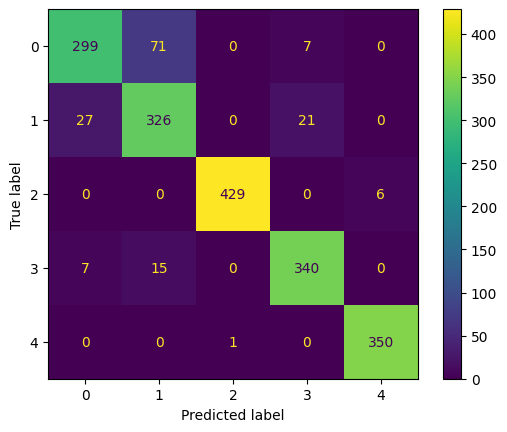

In [188]:
disp.plot()

In [189]:
print(classification_report(y_validation_inverse, classes_x))

              precision    recall  f1-score   support

           0       0.90      0.79      0.84       377
           1       0.79      0.87      0.83       374
           2       1.00      0.99      0.99       435
           3       0.92      0.94      0.93       362
           4       0.98      1.00      0.99       351

    accuracy                           0.92      1899
   macro avg       0.92      0.92      0.92      1899
weighted avg       0.92      0.92      0.92      1899



In [190]:
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay,classification_report,accuracy_score
# Calculate accuracy for each class
class_accuracies = {}
for cls in np.unique(classes_x):
    class_mask = (y_validation_inverse == cls)
    class_accuracies[f"Class {cls}"] = accuracy_score(y_validation_inverse[class_mask], classes_x[class_mask])

# Print class-wise accuracies
print("Accuracy for each class:")
for cls, acc in class_accuracies.items():
    print(f"{cls}: {acc:.2f}")

Accuracy for each class:
Class 0: 0.79
Class 1: 0.87
Class 2: 0.99
Class 3: 0.94
Class 4: 1.00


In [191]:
from sklearn.metrics import confusion_matrix, classification_report
import numpy as np

# Example function to calculate per-class accuracy
def calculate_per_class_accuracy(y_true, y_pred, class_names=None):
    """
    Calculate accuracy for each class.
    
    Parameters:
    - y_true: Ground truth labels (list or numpy array).
    - y_pred: Predicted labels (list or numpy array).
    - class_names: List of class names (optional).
    
    Returns:
    - A dictionary with class-wise accuracies.
    """
    # Generate confusion matrix
    cm = confusion_matrix(y_true, y_pred)
    
    # Calculate accuracy for each class
    per_class_accuracy = cm.diagonal() / cm.sum(axis=1)
    
    # Organize results
    results = {}
    if class_names is None:
        class_names = [f'Class {i}' for i in range(len(per_class_accuracy))]
    for class_name, accuracy in zip(class_names, per_class_accuracy):
        results[class_name] = accuracy
    
    return results

# Example usage
if __name__ == "__main__":
    # Example true and predicted labels
    #y_true = [0, 1, 2, 2, 0, 1, 1, 0, 2, 1]  # Ground truth
    #y_pred = [0, 1, 1, 2, 0, 1, 2, 0, 2, 1]  # Predictions
    
    # Class names (optional)
    class_names = [0, 1, 2,3,4,5,6]
    
    # Calculate and display per-class accuracy
    accuracy_per_class = calculate_per_class_accuracy(y_validation_inverse, classes_x, class_names)
    for class_name, accuracy in accuracy_per_class.items():
        print(f"{class_name}: {accuracy:.2f}")
    
    # Display class


0: 0.79
1: 0.87
2: 0.99
3: 0.94
4: 1.00


In [192]:
print(classification_report(y_validation_inverse, classes_x))

              precision    recall  f1-score   support

           0       0.90      0.79      0.84       377
           1       0.79      0.87      0.83       374
           2       1.00      0.99      0.99       435
           3       0.92      0.94      0.93       362
           4       0.98      1.00      0.99       351

    accuracy                           0.92      1899
   macro avg       0.92      0.92      0.92      1899
weighted avg       0.92      0.92      0.92      1899



In [ ]:
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay,classification_report,accuracy_score
# Calculate accuracy for each class
class_accuracies = {}
for cls in np.unique(classes_x):
    class_mask = (y_validation_inverse == cls)
    class_accuracies[f"Class {cls}"] = accuracy_score(y_validation_inverse[class_mask], classes_x[class_mask])

# Print class-wise accuracies
print("Accuracy for each class:")
for cls, acc in class_accuracies.items():
    print(f"{cls}: {acc:.2f}")

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report
import numpy as np

# Example function to calculate per-class accuracy
def calculate_per_class_accuracy(y_true, y_pred, class_names=None):
    """
    Calculate accuracy for each class.
    
    Parameters:
    - y_true: Ground truth labels (list or numpy array).
    - y_pred: Predicted labels (list or numpy array).
    - class_names: List of class names (optional).
    
    Returns:
    - A dictionary with class-wise accuracies.
    """
    # Generate confusion matrix
    cm = confusion_matrix(y_true, y_pred)
    
    # Calculate accuracy for each class
    per_class_accuracy = cm.diagonal() / cm.sum(axis=1)
    
    # Organize results
    results = {}
    if class_names is None:
        class_names = [f'Class {i}' for i in range(len(per_class_accuracy))]
    for class_name, accuracy in zip(class_names, per_class_accuracy):
        results[class_name] = accuracy
    
    return results

# Example usage
if __name__ == "__main__":
    # Example true and predicted labels
    #y_true = [0, 1, 2, 2, 0, 1, 1, 0, 2, 1]  # Ground truth
    #y_pred = [0, 1, 1, 2, 0, 1, 2, 0, 2, 1]  # Predictions
    
    # Class names (optional)
    class_names = [0, 1, 2,3,4,5,6]
    
    # Calculate and display per-class accuracy
    accuracy_per_class = calculate_per_class_accuracy(y_validation_inverse, classes_x, class_names)
    for class_name, accuracy in accuracy_per_class.items():
        print(f"{class_name}: {accuracy:.2f}")
    
    # Display class


In [ ]:
best_model.save(WORKDIR+"/Model/best_models_saved_"+data_hora)